In [1]:
import scanpy as sc
import pandas as pd
import numpy as np

In [ ]:
adata = sc.read_h5ad('./data/scncc_with_nocancer_anno.h5ad')

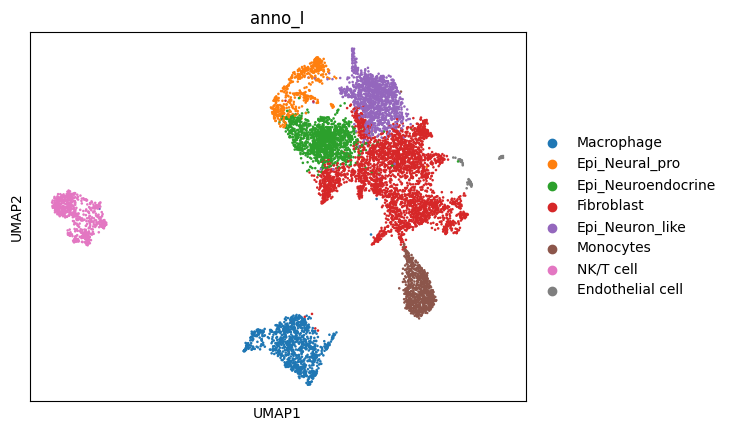

In [ ]:
sc.pl.umap(adata, color='anno_I')

In [ ]:
select_ct = ['Fibroblast']
sub_adata = adata[adata.obs['anno_I'].isin(select_ct)].copy()
sub_adata

AnnData object with n_obs × n_vars = 3051 × 18939
    obs: 'barcodes', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'total_counts_hsp', 'pct_counts_hsp', 'n_genes', 'group', 'predicted_celltype', 'predicted_probability', 'leiden', 'anno_I'
    var: 'mt', 'rb', 'hb', 'hsp', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'anno_I_colors', 'batch_colors', 'group_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'over_clustering', 'pca', 'predicted_celltype_colors', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [ ]:
sub_adata.X = sub_adata.layers['counts'].copy()
sc.pp.filter_genes(sub_adata, min_cells=3)
sub_adata

AnnData object with n_obs × n_vars = 3051 × 16197
    obs: 'barcodes', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'total_counts_hsp', 'pct_counts_hsp', 'n_genes', 'group', 'predicted_celltype', 'predicted_probability', 'leiden', 'anno_I'
    var: 'mt', 'rb', 'hb', 'hsp', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'anno_I_colors', 'batch_colors', 'group_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'over_clustering', 'pca', 'predicted_celltype_colors', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [ ]:
sc.pp.normalize_total(sub_adata, target_sum=1e4)
sc.pp.log1p(sub_adata)

In [ ]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    layer="counts",
    flavor="seurat_v3",
    batch_key="batch",
)

In [ ]:
sc.pp.regress_out(sub_adata, ["total_counts", "pct_counts_mt", 'n_genes_by_counts'], n_jobs=4)

In [ ]:
sc.pp.pca(sub_adata, svd_solver="arpack")

In [10]:
sc.external.pp.harmony_integrate(sub_adata, key='batch', max_iter_harmony=20)

2025-12-02 10:42:00,435 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-12-02 10:42:20,446 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-12-02 10:42:20,579 - harmonypy - INFO - Iteration 1 of 20
2025-12-02 10:42:27,144 - harmonypy - INFO - Iteration 2 of 20
2025-12-02 10:42:33,361 - harmonypy - INFO - Iteration 3 of 20
2025-12-02 10:42:39,751 - harmonypy - INFO - Iteration 4 of 20
2025-12-02 10:42:43,298 - harmonypy - INFO - Iteration 5 of 20
2025-12-02 10:42:46,910 - harmonypy - INFO - Iteration 6 of 20
2025-12-02 10:42:50,724 - harmonypy - INFO - Iteration 7 of 20
2025-12-02 10:42:53,583 - harmonypy - INFO - Iteration 8 of 20
2025-12-02 10:42:57,256 - harmonypy - INFO - Iteration 9 of 20
2025-12-02 10:43:00,224 - harmonypy - INFO - Iteration 10 of 20
2025-12-02 10:43:03,439 - harmonypy - INFO - Iteration 11 of 20
2025-12-02 10:43:05,475 - harmonypy - INFO - Iteration 12 of 20
2025-12-02 10:43:08,824 - harmonypy - INFO - Iteration 13 of

In [11]:
sc.pp.neighbors(sub_adata, n_neighbors=20, use_rep="X_pca_harmony", random_state=0)

/usr/local/lib/python3.9/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [14]:
sc.tl.leiden(sub_adata, resolution = 0.3, flavor = 'igraph', n_iterations=-1)
sc.tl.umap(sub_adata, min_dist=0.1)

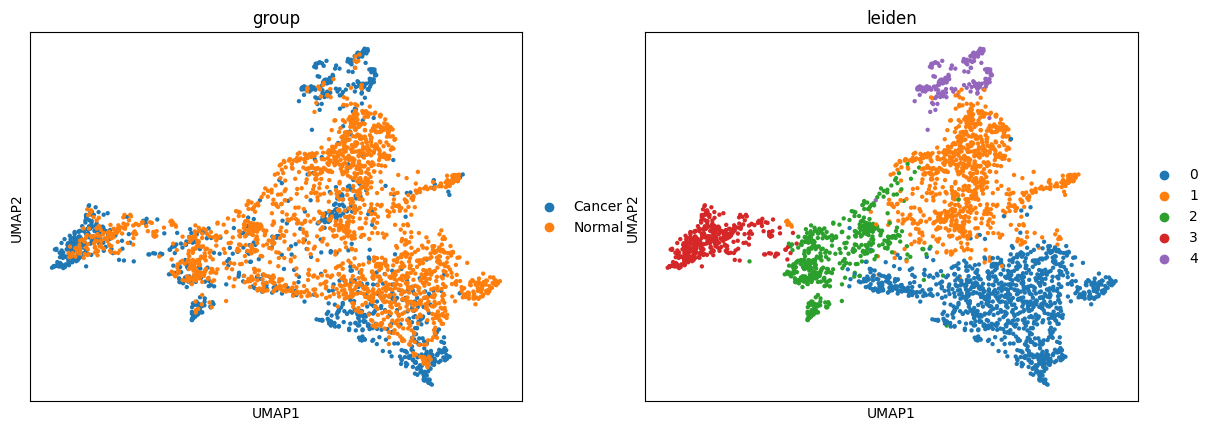

In [15]:
sc.pl.umap(sub_adata, color=['group', 'leiden'])

In [16]:
sc.tl.rank_genes_groups(sub_adata, "leiden", method="wilcoxon")

In [17]:
dfs = []
for g in sub_adata.obs["leiden"].cat.categories:
    df = sc.get.rank_genes_groups_df(sub_adata, group=g)
    df["cluster"] = g
    dfs.append(df)
markers = pd.concat(dfs, ignore_index=True)

In [18]:
marker_df = markers.assign(row_index=markers.groupby('cluster').cumcount()).pivot_table(index='row_index', columns='cluster', values='names',  aggfunc='first')
marker_df.index.name = None
marker_df.columns.name = None
marker_df.loc[1:100].to_csv('sub_fibroblast_marker.csv')

In [20]:
anno_mapping = {
    # Stress-response
    "0": "sc_Fibro", # HSP90AA1 HSPA1B SOX4 JUN
    "1": "myo_CAF", # CALD1, IGFBP7, TPM2
    "2": "i_CAF", # CFD, DUSP1, FBLN1
    "3": "pro_Fibro", # ACTB RPLP1/4/9/34/36A
    "4": "ecm_CAF" # SPARC, TGFBI, TIMP1, S100A6/10, MT1E/X/G
}

sub_adata.obs['anno_II'] = sub_adata.obs['leiden'].replace(anno_mapping)

In [21]:
marker_dict = {
    "sc_Fibro": [i for i in ["HSP90AA1", "HSPA1B", "SOX4", "JUN"] if i in sub_adata.var_names],
    "myo_CAF": [i for i in ["CALD1", "IGFBP7", "TPM2"] if i in sub_adata.var_names],
    "i_CAF": [i for i in ["CFD", "DUSP1", "FBLN1"] if i in sub_adata.var_names],
    "pro_Fibro": [i for i in ["ACTB", "RPLP1", "RPLP4"] if i in sub_adata.var_names],
    "ecm_CAF": ["SPARC", "TGFBI", "TIMP1", "S100A6", "MT1E"]
}

In [22]:
import seaborn as sns
from matplotlib import colors
import matplotlib.pyplot as plt

import matplotlib.font_manager as fm
font_dir = '/data/work/GZ_lab/ovarian/font/'
for ttf in fm.findSystemFonts(font_dir):
    fm.fontManager.addfont(ttf)

import matplotlib
plt.rcParams['font.family'] = 'Times New Roman'
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

import logging
logging.getLogger("fontTools.subset").setLevel(logging.WARNING)

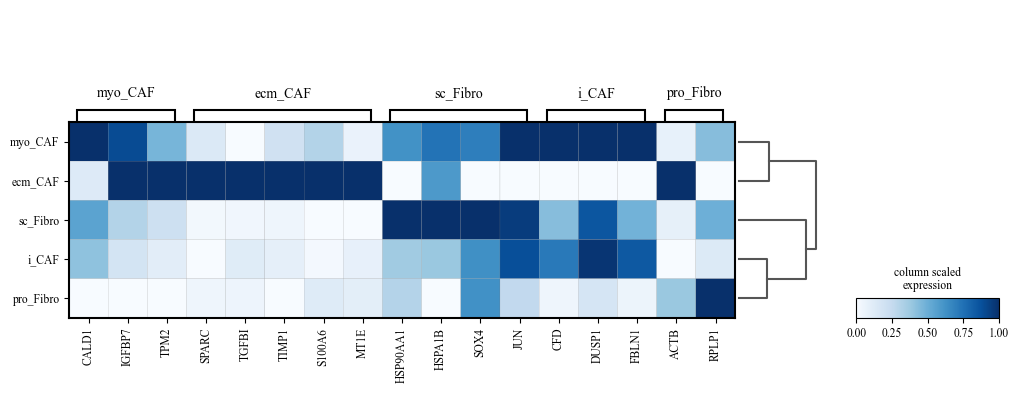

In [24]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))
sc.pl.matrixplot(sub_adata, marker_dict, 'anno_II', cmap='Blues', dendrogram=True, standard_scale="var", colorbar_title='column scaled\nexpression', ax=ax, var_group_rotation=0, show=False)
plt.savefig('./fig/figs3_fibro_marker_expression.pdf', format='pdf')

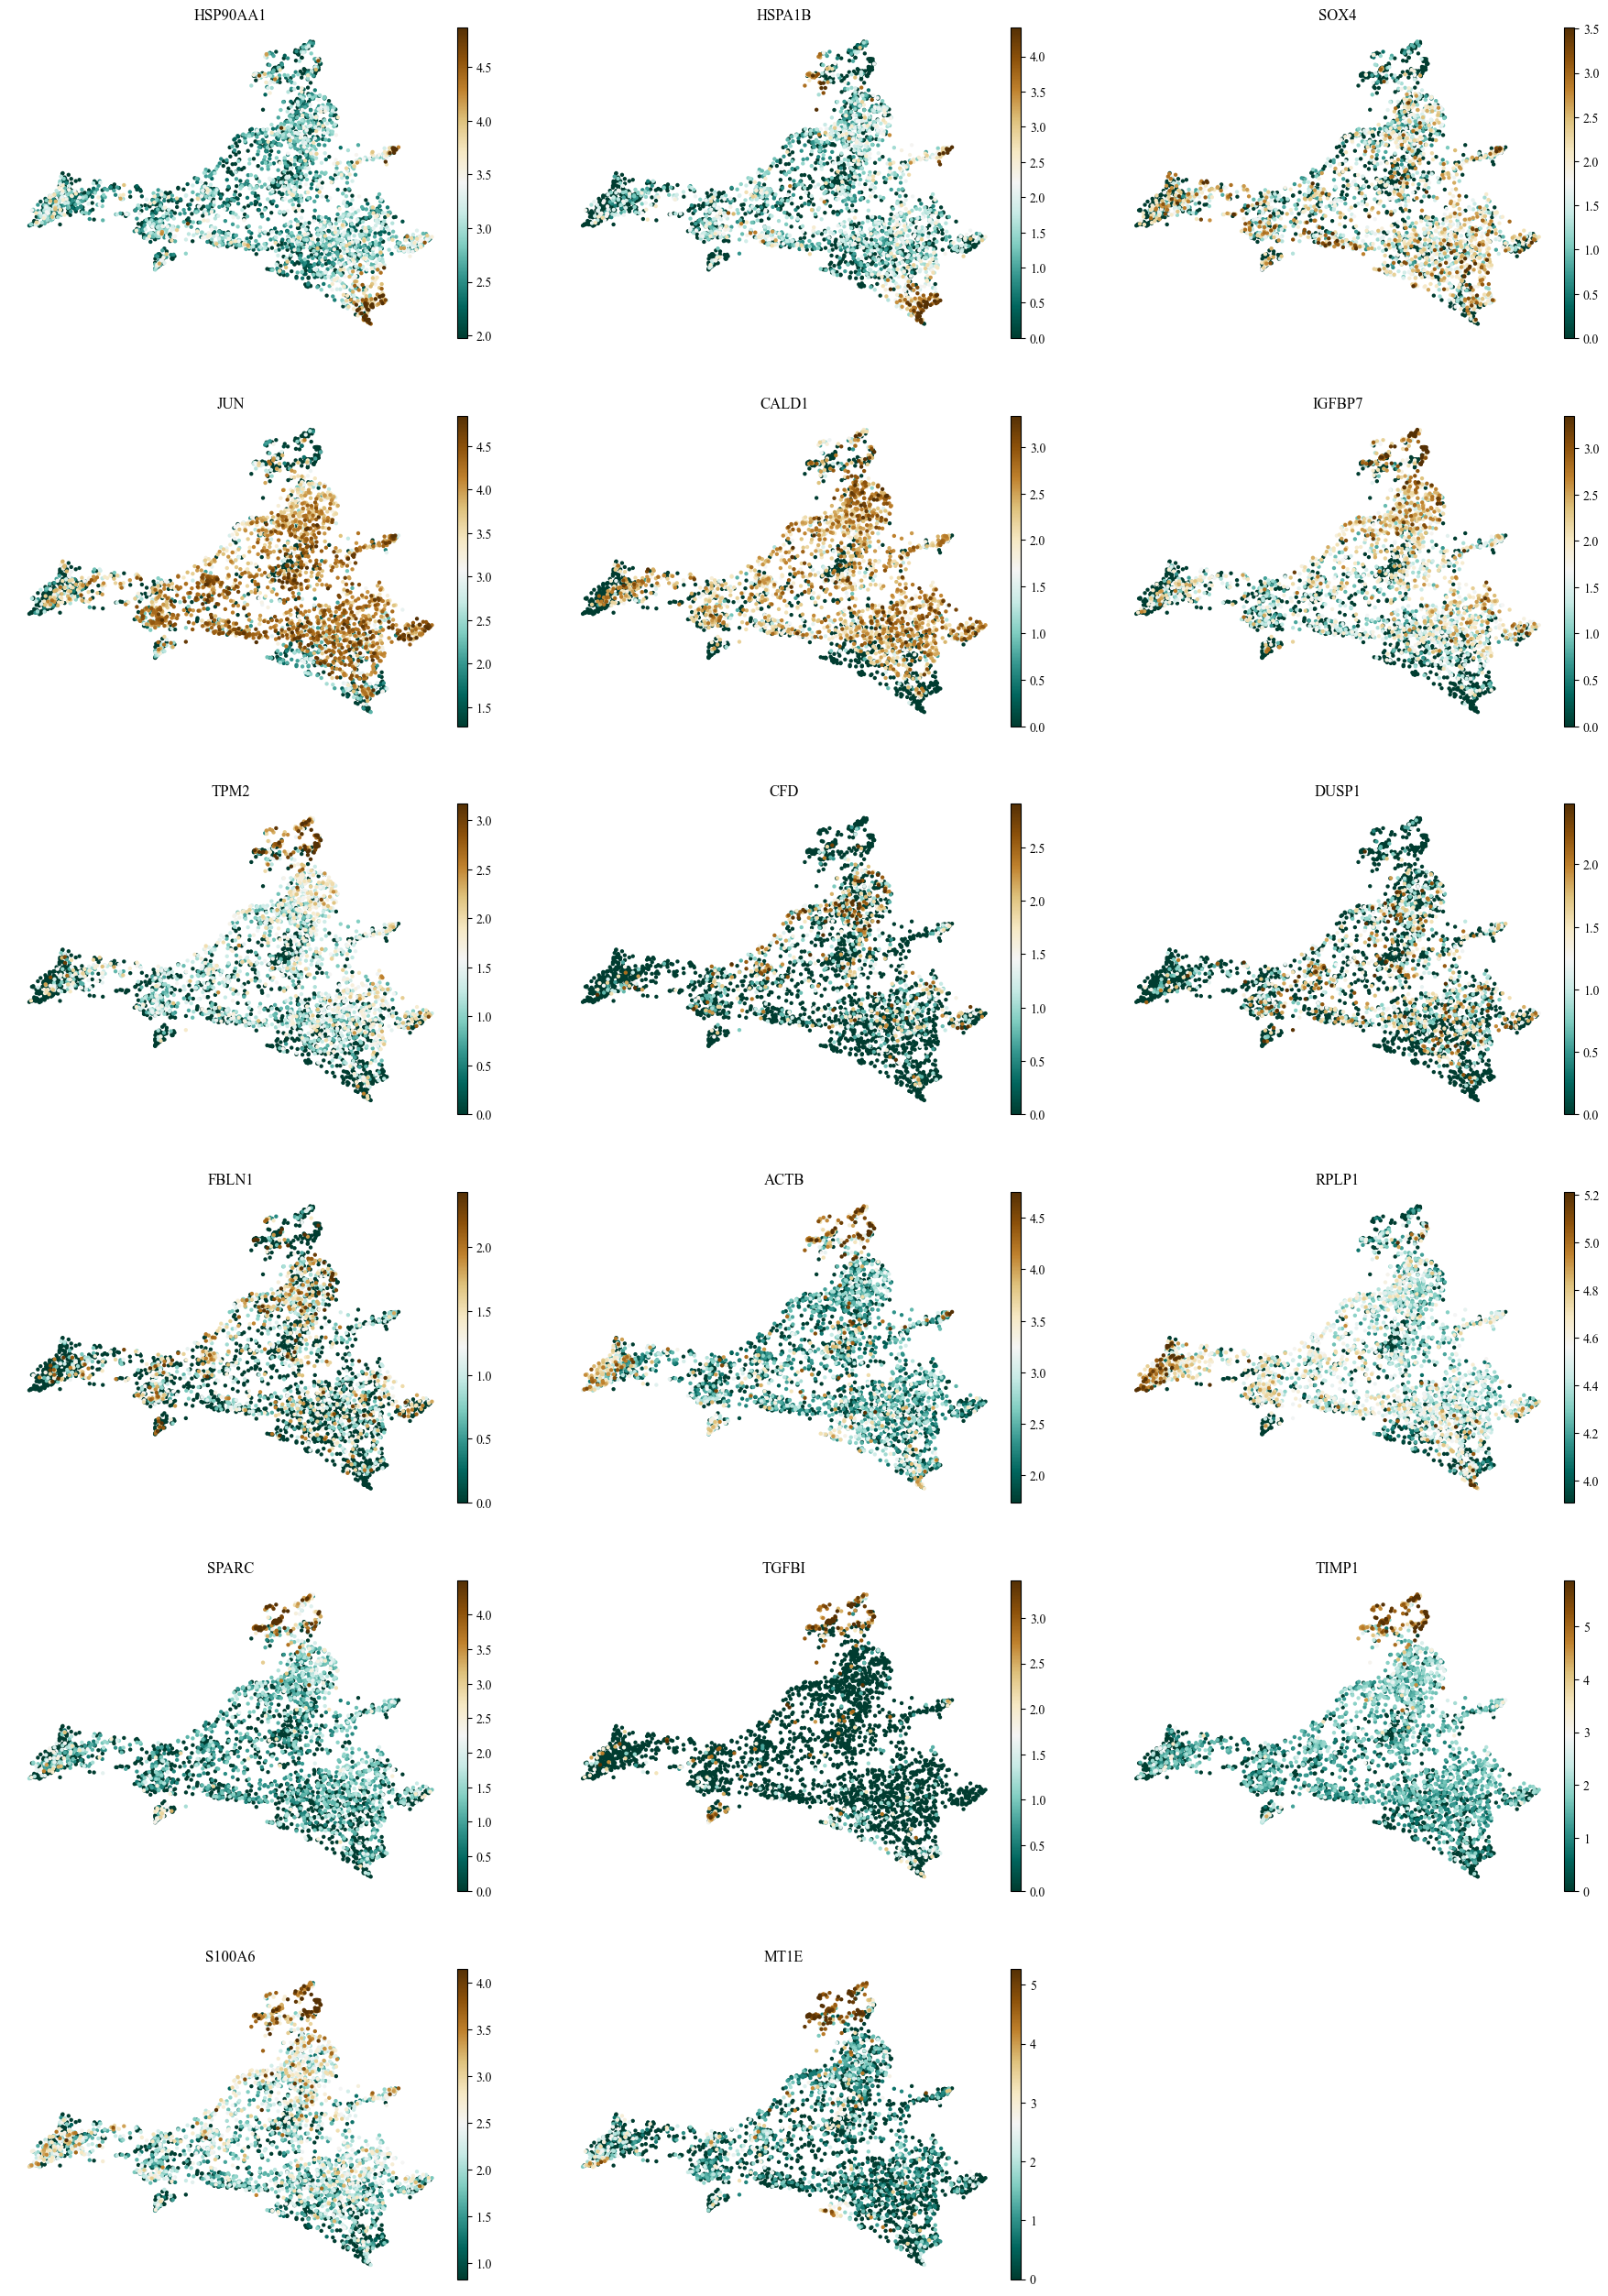

In [48]:
sc.pl.umap(sub_adata, color=[gene for sublist in marker_dict.values() for gene in sublist], vmax='p99', vmin='p20', ncols=3, cmap='BrBG_r', frameon=False, show=False)
plt.savefig('./fig/figs3_fibro_anno_umap.pdf', format='pdf', bbox_inches='tight', pad_inches=0.2)
plt.show()

/usr/local/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


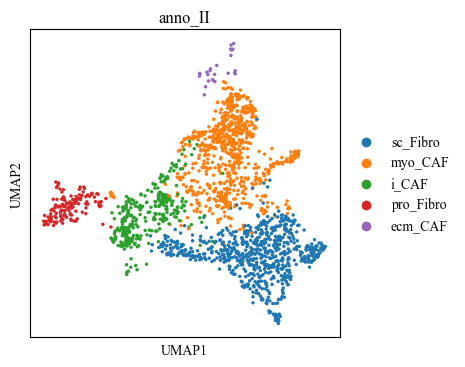

In [49]:
fig, ax = plt.subplots(figsize=(4, 4))
sc.pl.umap(sub_adata[sub_adata.obs['group'] == 'Normal'], color='anno_II', show=False, ax=ax, size=25)
plt.savefig('./fig/figs3_fibro_normal_umap.pdf', format='pdf')

/usr/local/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


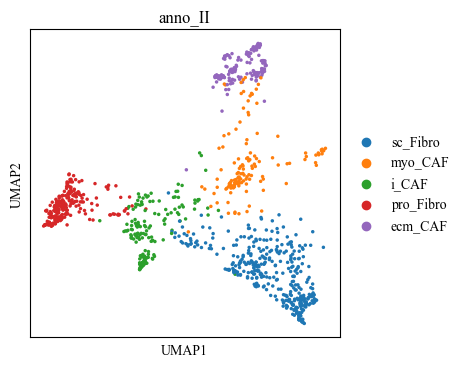

In [50]:
fig, ax = plt.subplots(figsize=(4, 4))
sc.pl.umap(sub_adata[sub_adata.obs['group'] == 'Cancer'], color='anno_II', show=False, ax=ax, size=25)
plt.savefig('./fig/figs3_fibro_cancer_umap.pdf', format='pdf')

In [51]:
df = pd.crosstab(sub_adata.obs['group'], sub_adata.obs['anno_II']).div(pd.crosstab(sub_adata.obs['group'], sub_adata.obs['anno_II']).sum(axis=1), axis=0)

In [52]:
df

anno_II,sc_Fibro,myo_CAF,i_CAF,pro_Fibro,ecm_CAF
group,,,,,
Cancer,0.352941,0.125000,0.159926,0.208640,0.153493
Normal,0.368823,0.382578,0.164035,0.071829,0.012736


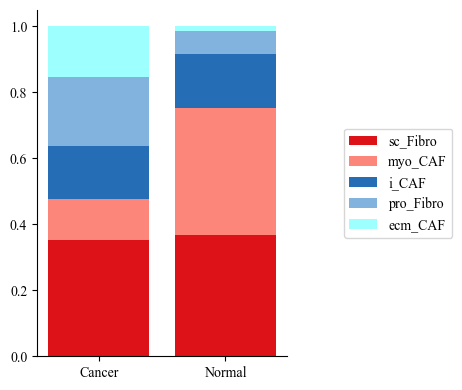

In [53]:
fig, ax = plt.subplots(figsize=(5, 4))

celltype2color = {
    'sc_Fibro': '#DC050C',
    'myo_CAF': '#FB8072',
    'i_CAF': '#1965B0',
    'pro_Fibro': '#7BAFDE',
    "ecm_CAF": "#99FFFF"
}

bottom = [0] * len(df)
for ct in df.columns:
    ax.bar(df.index, df[ct], bottom=bottom, label=ct, alpha=0.95, color=celltype2color[ct])
    bottom = [i+j for i,j in zip(bottom, df[ct])]
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
    
ax.legend(title="", loc='center left', bbox_to_anchor=(1.2, 0.5))
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("./fig/figs3_cancer-normal_ratio.pdf", format='pdf')
plt.show()

In [54]:
df = pd.crosstab(sub_adata.obs['anno_II'], sub_adata.obs['group']).div(pd.crosstab(sub_adata.obs['anno_II'], sub_adata.obs['group']).sum(axis=1), axis=0)
df

group,Cancer,Normal
anno_II,,
sc_Fibro,0.346570,0.653430
myo_CAF,0.153326,0.846674
i_CAF,0.350806,0.649194
pro_Fibro,0.616848,0.383152
ecm_CAF,0.869792,0.130208


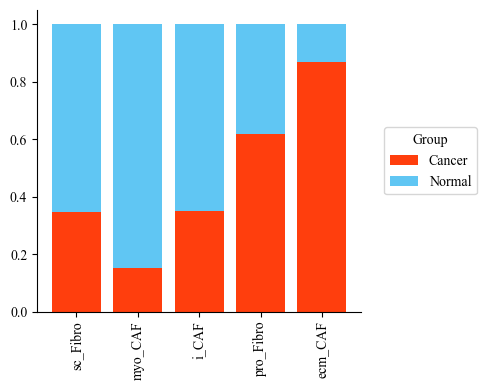

In [55]:
fig, ax = plt.subplots(figsize=(5, 4))

group2color = {'Cancer': '#FF3300', 'Normal': '#57C3F3'}

bottom = [0] * len(df)
for ct in df.columns:
    ax.bar(df.index, df[ct], bottom=bottom, label=ct, alpha=0.95, color=group2color[ct])
    bottom = [i+j for i,j in zip(bottom, df[ct])]
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
    
handles, labels = ax.get_legend_handles_labels()
labels = ['normal' if l == 'non-cancer' else l for l in labels]

legend = ax.legend(handles, labels,
    title = 'Group',
    loc ='center left',
    bbox_to_anchor=(1.05, 0.5),
    frameon = True)
                   
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("./fig/figs3_cancervsnormal_ratio.pdf", format='pdf')
plt.show()

In [57]:
sub_adata.write_h5ad('sub_fibroblast.h5ad')

In [58]:
import gseapy as gp

In [59]:
sc.tl.rank_genes_groups(sub_adata, groupby="anno_II")

In [60]:
ranked_dict = {}
for clust in sub_adata.obs['anno_II'].cat.categories:
    df = sc.get.rank_genes_groups_df(sub_adata, group=clust, key='rank_genes_groups')
    df = df.dropna()
    df = df.sort_values('logfoldchanges', ascending=False)  # 降序
    ranked_dict[clust] = df['names'].tolist()

In [67]:
gmt_path = "/data/work/GZ_lab/ovarian/gmt/c5.go.bp.v2025.1.Hs.symbols.gmt"

In [77]:
enrich_dict = {}
for ct, gene_list in ranked_dict.items():
    enr_res = gp.enrichr(gene_list[:50],
              gene_sets=gmt_path,
              outdir=None)
    enr_res.res2d.Term = enr_res.res2d.Term.str.split(" \(GO").str[0]
    enrich_dict[ct] = enr_res.res2d

In [93]:
top_list = []
for ct, df in enrich_dict.items():
    df = df.sort_values(by="Adjusted P-value")[:5]
    df["celltype"] = ct
    top_list.append(df)

df_total = pd.concat(top_list, ignore_index=True)
df_total

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Odds Ratio,Combined Score,Genes,celltype
0,c5.go.bp.v2025.1.Hs.symbols.gmt,GOBP_POSITIVE_REGULATION_OF_CILIUM_MOVEMENT,1/16,0.030674,0.252687,50.352034,175.443442,TAC4,sc_Fibro
1,c5.go.bp.v2025.1.Hs.symbols.gmt,GOBP_POSITIVE_REGULATION_OF_LONG_TERM_SYNAPTIC...,1/24,0.045666,0.252687,33.196115,102.456231,SHISA7,sc_Fibro
2,c5.go.bp.v2025.1.Hs.symbols.gmt,GOBP_LOOP_OF_HENLE_DEVELOPMENT,1/12,0.023092,0.252687,67.880907,255.792381,HES5,sc_Fibro
3,c5.go.bp.v2025.1.Hs.symbols.gmt,GOBP_LYMPHOID_PROGENITOR_CELL_DIFFERENTIATION,1/24,0.045666,0.252687,33.196115,102.456231,HES5,sc_Fibro
4,c5.go.bp.v2025.1.Hs.symbols.gmt,GOBP_L_AMINO_ACID_CATABOLIC_PROCESS,2/78,0.010055,0.252687,17.451468,80.271257,ARG1;HAL,sc_Fibro
5,c5.go.bp.v2025.1.Hs.symbols.gmt,GOBP_DISRUPTION_OF_CELLULAR_ANATOMICAL_STRUCTU...,2/6,0.000058,0.039469,289.219002,2821.135042,DEFA4;DEFA3,myo_CAF
6,c5.go.bp.v2025.1.Hs.symbols.gmt,GOBP_CELLULAR_RESPONSE_TO_MOLECULE_OF_BACTERIA...,5/250,0.000132,0.044767,12.602366,112.605005,DEFA4;DEFA3;CEBPE;MMP8;TLR10,myo_CAF
7,c5.go.bp.v2025.1.Hs.symbols.gmt,GOBP_CELLULAR_RESPONSE_TO_LIPID,7/652,0.000264,0.044952,6.821476,56.194996,DEFA4;WNT8B;DEFA3;RAMP3;MMP8;CEBPE;SOX10,myo_CAF
8,c5.go.bp.v2025.1.Hs.symbols.gmt,GOBP_CELLULAR_RESPONSE_TO_BIOTIC_STIMULUS,5/277,0.000212,0.044952,11.336391,95.875611,DEFA4;DEFA3;CEBPE;MMP8;TLR10,myo_CAF
9,c5.go.bp.v2025.1.Hs.symbols.gmt,GOBP_RESPONSE_TO_LIPID,8/955,0.000488,0.066436,5.356617,40.839783,DEFA4;WNT8B;DEFA3;ILDR1;RAMP3;MMP8;CEBPE;SOX10,myo_CAF


In [94]:
df_total['-log10(adjusted p)'] = -np.log10(df_total["Adjusted P-value"])

In [95]:
df_total['Term'] = df_total.Term.str.strip("GOBP_").str.lower()
df_total

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Odds Ratio,Combined Score,Genes,celltype,-log10(adjusted p)
0,c5.go.bp.v2025.1.Hs.symbols.gmt,sitive_regulation_of_cilium_movement,1/16,0.030674,0.252687,50.352034,175.443442,TAC4,sc_Fibro,0.597417
1,c5.go.bp.v2025.1.Hs.symbols.gmt,sitive_regulation_of_long_term_synaptic_potent...,1/24,0.045666,0.252687,33.196115,102.456231,SHISA7,sc_Fibro,0.597417
2,c5.go.bp.v2025.1.Hs.symbols.gmt,loop_of_henle_development,1/12,0.023092,0.252687,67.880907,255.792381,HES5,sc_Fibro,0.597417
3,c5.go.bp.v2025.1.Hs.symbols.gmt,lymphoid_progenitor_cell_differentiation,1/24,0.045666,0.252687,33.196115,102.456231,HES5,sc_Fibro,0.597417
4,c5.go.bp.v2025.1.Hs.symbols.gmt,l_amino_acid_catabolic_process,2/78,0.010055,0.252687,17.451468,80.271257,ARG1;HAL,sc_Fibro,0.597417
5,c5.go.bp.v2025.1.Hs.symbols.gmt,disruption_of_cellular_anatomical_structure_in...,2/6,0.000058,0.039469,289.219002,2821.135042,DEFA4;DEFA3,myo_CAF,1.403739
6,c5.go.bp.v2025.1.Hs.symbols.gmt,cellular_response_to_molecule_of_bacterial_origin,5/250,0.000132,0.044767,12.602366,112.605005,DEFA4;DEFA3;CEBPE;MMP8;TLR10,myo_CAF,1.349041
7,c5.go.bp.v2025.1.Hs.symbols.gmt,cellular_response_to_lipid,7/652,0.000264,0.044952,6.821476,56.194996,DEFA4;WNT8B;DEFA3;RAMP3;MMP8;CEBPE;SOX10,myo_CAF,1.347248
8,c5.go.bp.v2025.1.Hs.symbols.gmt,cellular_response_to_biotic_stimulus,5/277,0.000212,0.044952,11.336391,95.875611,DEFA4;DEFA3;CEBPE;MMP8;TLR10,myo_CAF,1.347248
9,c5.go.bp.v2025.1.Hs.symbols.gmt,response_to_lipid,8/955,0.000488,0.066436,5.356617,40.839783,DEFA4;WNT8B;DEFA3;ILDR1;RAMP3;MMP8;CEBPE;SOX10,myo_CAF,1.177598


In [96]:
plot_df = pd.pivot(df_total, index="celltype", columns='Term', values='-log10(adjusted p)').fillna(0)
plot_df

Term,acute_phase_response,amide_transport,antibacterial_peptide_production,antimicrobial_peptide_production,cellular_response_to_biotic_stimulus,cellular_response_to_lipid,cellular_response_to_molecule_of_bacterial_origin,defense_response_to_bacterium,digestion,disruption_of_cellular_anatomical_structure_in_another_organism,...,lymphoid_progenitor_cell_differentiation,regulation_of_bone_remodelin,regulation_of_fever_generation,regulation_of_peptide_transport,response_to_lipid,rotein_coupled_receptor_signaling_pathway,secretion,sitive_regulation_of_cilium_movement,sitive_regulation_of_fever_generation,sitive_regulation_of_long_term_synaptic_potentiation
celltype,,,,,,,,,,,,,,,,,,,,,
ecm_CAF,1.685032,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,1.685032,1.685032,0.000000,0.000000,0.000000,0.000000,0.000000,1.685032,0.000000
i_CAF,0.000000,0.000000,1.393571,1.386503,0.000000,0.000000,0.000000,1.350592,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
myo_CAF,0.000000,0.000000,0.000000,0.000000,1.347248,1.347248,1.349041,0.000000,0.000000,1.403739,...,0.000000,0.000000,0.000000,0.000000,1.177598,0.000000,0.000000,0.000000,0.000000,0.000000
pro_Fibro,0.000000,1.366303,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.366303,0.000000,...,0.000000,0.000000,0.000000,1.208925,0.000000,1.366303,1.366303,0.000000,0.000000,0.000000
sc_Fibro,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.597417,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.597417,0.000000,0.597417


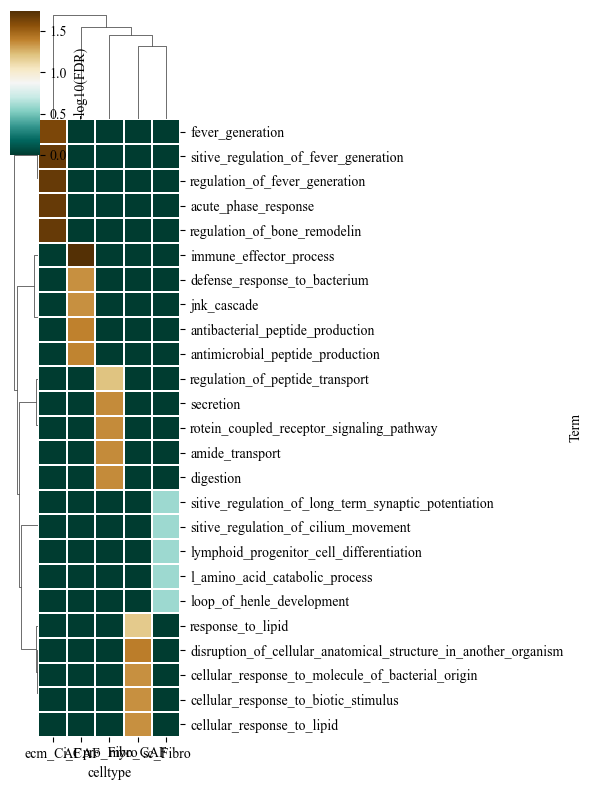

In [103]:
sns.clustermap(plot_df.T,
               cmap='BrBG_r',
               metric='euclidean',
               method='average',
               linewidths=.01,
               figsize=(6, 8),
               dendrogram_ratio=0.15,
               cbar_kws={'label': '-log10(FDR)'})
plt.savefig("./fig/figs3_GO_BP_heatmap_top5.pdf", bbox_inches='tight')
plt.show()